In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy as sp

In [2]:
class clickGenerator:

    def __init__(self, ctr):
        self.ctr = ctr
        #self.click_sample_size = click_sample_size

    # click binomial function generator

    def generateClicks(self, click_sample_size):
        return np.random.binomial(n=1, p=self.ctr, size=click_sample_size)

In [3]:
control_version = clickGenerator(0.05)
treatment_version = clickGenerator(0.0525)

In [4]:
class ABTest:

    def __init__(self,seed_value, early_stopping, total_sample_size, version_A, version_B ):
        self.seed_value = seed_value
        self.early_stopping = early_stopping
        #self.p_threshold = p_threshold
        self.total_sample_size = total_sample_size
        #self.peeking_freq = peeking_freq
        self.version_A = version_A
        self.version_B = version_B

    @staticmethod
    def sample_size_func(ctr, significance_level, power, mde):
        
        #ctr = 0.05
        #significance_level = 0.05
        #power = 0.80
        #mde = 0.0025
        z_alpha = sp.stats.norm.ppf(1 - (significance_level / 2))
        z_beta = sp.stats.norm.ppf(power)
        variance = ctr * (1 - ctr)
        sample_size = (2 * (z_alpha + z_beta)**2  * variance)/ (mde**2) 

        #self.sample_size = sample_size
        print(f"Sample size needed is {int(sample_size)} per variation")

    def cdf_func(self,p_values):
        return np.sort(p_values), np.arange(len(p_values)) / len(p_values)
    
    def z_score_func(self, sample_A, sample_B):
        
        x_A = sample_A.sum()
        x_B = sample_B.sum()
        n_A = sample_A.size
        n_B = sample_B.size
        p_A = (x_A / n_A)
        p_B = (x_B / n_B)
        p_hat = (x_A + x_B) / (n_A + n_B)

        SE = np.sqrt((p_hat * (1 - p_hat)) * ((1/n_A) + (1/n_B)))
        Z_Value = (p_A - p_B) / SE
        P_Value = sp.stats.norm.sf(abs(Z_Value)) * 2

        return Z_Value, P_Value   

    # func abtest for every step of peeking and record results
    def abtesting_func(self, p_threshold, peeking_freq):
          
          np.random.seed(self.seed_value)
          sample_range = np.linspace(0, self.total_sample_size, peeking_freq+1, dtype=int)
          sample_control_bag = np.array([])
          sample_treatment_bag = np.array([])
          sample_range_len = len(sample_range)
          sample_size_bag = np.zeros(sample_range_len)
          p_value_log = np.zeros(sample_range_len)
          z_value_log = np.zeros(sample_range_len)
          control_ctr = np.zeros(sample_range_len)
          treatment_ctr = np.zeros(sample_range_len)


          #p_value_log
          #print(early_stopping) 
          i = 0
          for _ in range(sample_range_len - 1):
              
              #print(sample_range[i+1], sample_range[i])
              sample_size = sample_range[i+1] - sample_range[i]
              #print(sample_size)
              sample_control = self.version_A.generateClicks(sample_size)
              sample_treatment = self.version_B.generateClicks(sample_size)
              sample_control_bag = np.concatenate((sample_control_bag, sample_control))
              sample_treatment_bag = np.concatenate((sample_treatment_bag, sample_treatment))
              sample_size_bag[i+1] = sample_range[i+1]
              control_ctr[i+1] = sample_control_bag.mean()
              treatment_ctr[i+1] = sample_treatment_bag.mean()
              z_value, p_value = self.z_score_func(sample_control_bag, sample_treatment_bag)
              z_value_log[i+1] = z_value
              p_value_log[i+1] = p_value
              total_sample_size_ =  sample_range[i+1]
              #print(sample_range[i+1], z_value, p_value)
              if self.early_stopping == True:
                if p_value <= p_threshold:
                    #print(p_value)
                    break
    
              i = i + 1 
          
          sample_size_bag_ = sample_size_bag[sample_size_bag !=0]
          p_value_log_ = p_value_log[p_value_log != 0]
          z_value_log_ = z_value_log[z_value_log != 0]
          control_ctr_ = control_ctr[control_ctr != 0]
          treatment_ctr_ = treatment_ctr[treatment_ctr != 0]
          return p_value_log_, z_value_log_, control_ctr_, treatment_ctr_, total_sample_size_, sample_size_bag_

    def simulation_func(self, simulation_trials, p_threshold, peeking_freq):

        #sim_logs = []
        p_distribution = np.zeros(simulation_trials)
        p_hits = 0
        total_sample_size = 0
        #simulation_trials = 1000
        for i in range(simulation_trials):
            p_value_log, z_value_log, control_ctr, treatment_ctr, sample_size, _ = self.abtesting_func(p_threshold,peeking_freq)
            #print(p_value_log)
            #print(treatment_ctr)
            #print(control_ctr)
            #sim_logs.append(z_value_log)
            p_distribution[i] = p_value_log[-1]
            total_sample_size = total_sample_size + sample_size
            if p_value_log[-1] <= 0.05:
                p_hits = p_hits + 1

        #sim_logs_ = np.array(sim_logs, dtype=object)
        p_sim_ratio = (p_hits/ simulation_trials)
        average_sample_size = (total_sample_size/ simulation_trials)
        #print(p_value_log[0])
        return p_sim_ratio, average_sample_size, p_distribution


In [5]:
def sequential_plot(sample_range, 
                    p_value_log, 
                    z_value_log, 
                    control_ctr, 
                    treatment_ctr):
    fig, axs = plt.subplots(3, 1, figsize=(8, 6))
    sns.lineplot(x=sample_range, y=p_value_log, color="mediumpurple",linewidth=2.5, alpha=1.0, ax=axs[0])
    axs[0].axhline(0.05, color="k", linestyle="--", label="0.05")
    axs[0].set_ylim(0.01, 1.0)
    axs[0].set_xlim(0, 122000)
    axs[0].legend()
    #axs[0].set(xlabel="sample size")
    axs[0].set(ylabel="p-value")
    axs[0].set_title("sequential p-value", weight=None)
    sns.lineplot(x=sample_range, y=z_value_log, color="mediumpurple",linewidth=2.5, alpha=1.0, ax=axs[1])
    axs[1].axhline(1.96, color="k", linestyle="--", label="+/- 1.96")
    axs[1].axhline(-1.96, color="k", linestyle="--")
    axs[1].set_ylim(-5, 5)
    #axs[1].set(xlabel="sample size")
    axs[1].set(ylabel="z-score")
    axs[1].set_title("sequential z-score", weight=None)
    axs[1].legend()
    sns.lineplot(x=sample_range, y=control_ctr, color="mediumpurple",linewidth=2.5, alpha=1.0, label="control", ax=axs[2])
    sns.lineplot(x=sample_range, y=treatment_ctr, color="violet",linewidth=2.5, label="treatment", alpha=1.0, ax=axs[2])
    axs[2].set_ylim(0.04, 0.06)
    axs[2].set(xlabel="sample size")
    axs[2].set(ylabel="CTR")
    axs[2].set_title("sequential CTR", weight=None)

    plt.tight_layout()

    return fig

In [6]:
def abtest_dignostic_plot(abtest, 
                          p_value_log, 
                          fh_sample_size,  
                          average_sample_size, 
                          title):
        
        p_x, p_y  = abtest.cdf_func(p_value_log)

        fig, ax = plt.subplots(1, 3, figsize=(8.5,3.0))
        sns.histplot(p_value_log, bins=20, stat='probability', color="mediumpurple", label="Histogram", ax=ax[0])
        ax[0].set_ylim(0.00, 0.2)
        ax[0].set_ylabel("p-values")
        ax[0].set_xlabel("Histogram")

        sns.lineplot(x=p_x, y=p_y, color="mediumpurple",linewidth=2.5, alpha=1.0, ax=ax[1])
        sns.lineplot(x=p_x, y=p_x,color="black",linewidth=1.5, alpha=0.6, ax=ax[1])
        ax[1].set_xlabel("CDF")

        sns.barplot(x=["Fixed Horizon", "Sequential"], 
                    y=[fh_sample_size, int(average_sample_size)],
                    color="mediumpurple", alpha = 1.0,  ax=ax[2])
        ax[2].set_ylabel("sample-size")
        fig.suptitle(title)
        plt.tight_layout();

        return fig

In [7]:
# Sample size calculation

ABTest.sample_size_func(ctr = 0.05,
                        significance_level = 0.05,
                        power = 0.80,
                        mde = 0.0025)

Sample size needed is 119302 per variation


In [8]:
exp_sample_size = 120000

In [9]:
# Peeking in AB Test without Early stopping
aatest_wo_es_fpr = ABTest(seed_value=1010,
                          early_stopping = False,
                          total_sample_size=exp_sample_size,
                           version_A=control_version,
                           version_B=control_version)

abtest_wo_es_power = ABTest(seed_value=1010,
                          early_stopping = True,
                          total_sample_size=exp_sample_size,
                           version_A=control_version,
                           version_B=treatment_version)

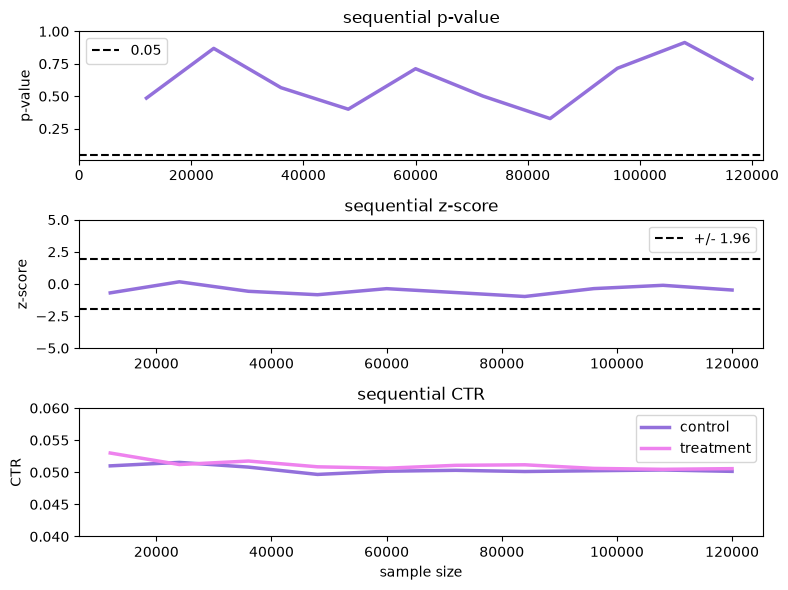

In [10]:
# Peeking in AA Test without Early stopping
p_threshold = 0.05
peeking_freq = 10
p_value_log_, z_value_log_, control_ctr_, treatment_ctr_, total_sample_size_, sample_size_bag_ = aatest_wo_es_fpr.abtesting_func(p_threshold=0.05,
                                                                                                               peeking_freq=peeking_freq)
_ = sequential_plot(sample_range=sample_size_bag_,
                     p_value_log=p_value_log_, 
                     z_value_log=z_value_log_, 
                     control_ctr=control_ctr_, 
                     treatment_ctr=treatment_ctr_)

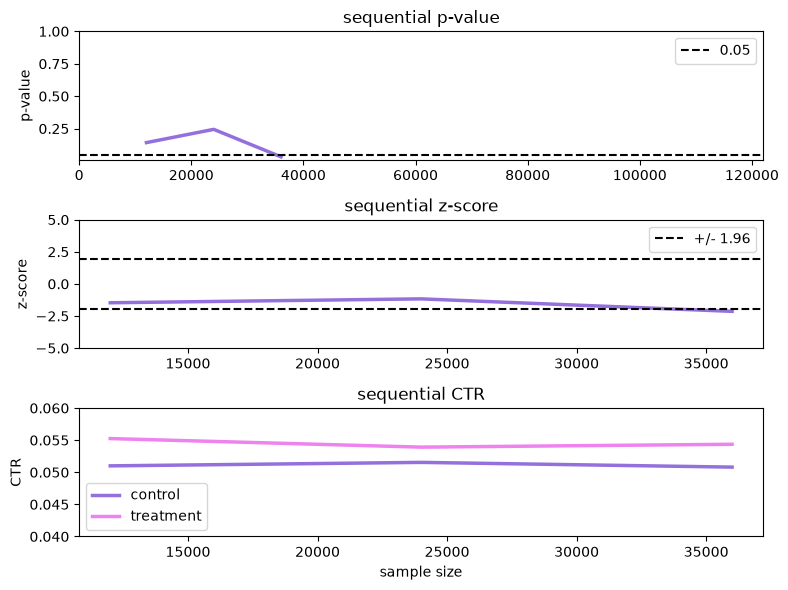

In [11]:
# Peeking in AB Test with Early stopping
p_threshold = 0.05
peeking_freq = 10
p_value_log_, z_value_log_, control_ctr_, treatment_ctr_, total_sample_size_, sample_size_bag_ = abtest_wo_es_power.abtesting_func(p_threshold=0.05,
                                                                                                                                   peeking_freq=peeking_freq)
_ = sequential_plot(sample_range=sample_size_bag_,
                     p_value_log=p_value_log_, 
                     z_value_log=z_value_log_, 
                     control_ctr=control_ctr_, 
                     treatment_ctr=treatment_ctr_)


In [12]:
# AA_test Simulation for FPR 
aatest_wo_es_fpr =  ABTest(seed_value=None,
                          early_stopping = False,
                          total_sample_size=exp_sample_size,
                           version_A=control_version,
                           version_B=control_version)

aatest_es_fpr =  ABTest(seed_value=None,
                          early_stopping = True,
                          total_sample_size=exp_sample_size,
                           version_A=control_version,
                           version_B=control_version)

abtest_wo_es_power =  ABTest(seed_value=None,
                             early_stopping = False,
                             total_sample_size=exp_sample_size,
                             version_A=control_version,
                             version_B=treatment_version)

abtest_es_power =  ABTest(seed_value=None,
                             early_stopping = True,
                             total_sample_size=exp_sample_size,
                             version_A=control_version,
                             version_B=treatment_version)


For 1000 Simulation Trials FPR Rate : 0.042 | Average Sample Size: 120000.0 


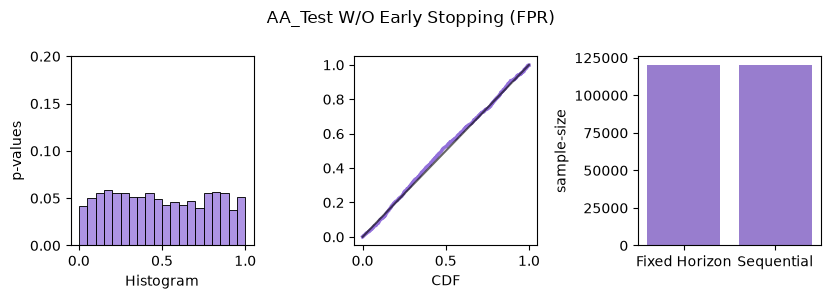

In [13]:
sims_trials = 1000
p_threshold = 0.05
peeking_freq = 10
p_sim_ratio, average_sample_size, p_distribution = aatest_wo_es_fpr.simulation_func(simulation_trials=sims_trials, 
                                                                    p_threshold = p_threshold, 
                                                                    peeking_freq = peeking_freq)

_ = abtest_dignostic_plot(abtest=aatest_wo_es_fpr,
                          p_value_log=p_distribution, 
                          fh_sample_size=exp_sample_size,  
                          average_sample_size = average_sample_size, 
                          title = "AA_Test W/O Early Stopping (FPR)")

print(f"For {sims_trials} Simulation Trials FPR Rate : {p_sim_ratio} | Average Sample Size: {average_sample_size} ")

For 1000 Simulation Trials FPR Rate : 0.206 | Average Sample Size: 104808.0 


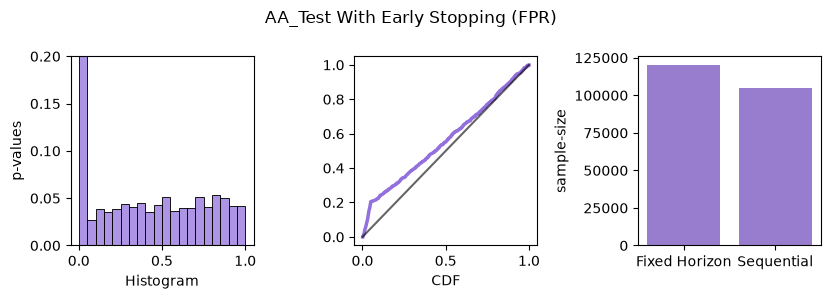

In [14]:
sims_trials = 1000
p_threshold = 0.05
peeking_freq = 10
p_sim_ratio, average_sample_size, p_distribution = aatest_es_fpr.simulation_func(simulation_trials=sims_trials, 
                                                                    p_threshold = p_threshold, 
                                                                    peeking_freq = peeking_freq)

_ = abtest_dignostic_plot(abtest=aatest_es_fpr,
                          p_value_log=p_distribution, 
                          fh_sample_size=exp_sample_size,  
                          average_sample_size = average_sample_size, 
                          title = "AA_Test With Early Stopping (FPR)")
print(f"For {sims_trials} Simulation Trials FPR Rate : {p_sim_ratio} | Average Sample Size: {average_sample_size} ")

For 1000 Simulation Trials Power Rate : 0.808 | Average Sample Size: 120000.0 


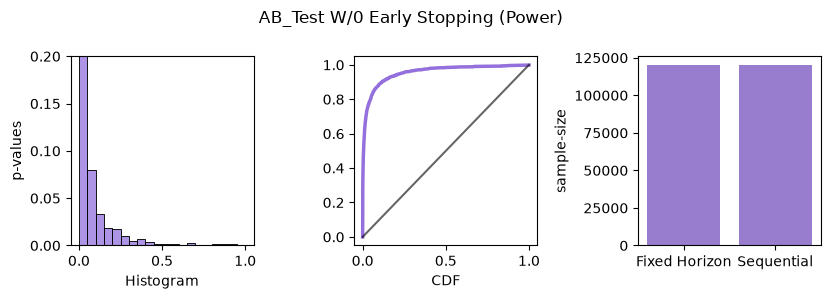

In [15]:
sims_trials = 1000
p_threshold = 0.05
peeking_freq = 10
p_sim_ratio, average_sample_size, p_distribution = abtest_wo_es_power.simulation_func(simulation_trials=sims_trials, 
                                                                    p_threshold = p_threshold, 
                                                                    peeking_freq = peeking_freq)

_ = abtest_dignostic_plot(abtest=abtest_wo_es_power,
                          p_value_log=p_distribution, 
                          fh_sample_size=exp_sample_size,  
                          average_sample_size = average_sample_size, 
                          title = "AB_Test W/0 Early Stopping (Power)")
print(f"For {sims_trials} Simulation Trials Power Rate : {p_sim_ratio} | Average Sample Size: {average_sample_size} ")

For 1000 Simulation Trials Power Rate : 0.878 | Average Sample Size: 58548.0 


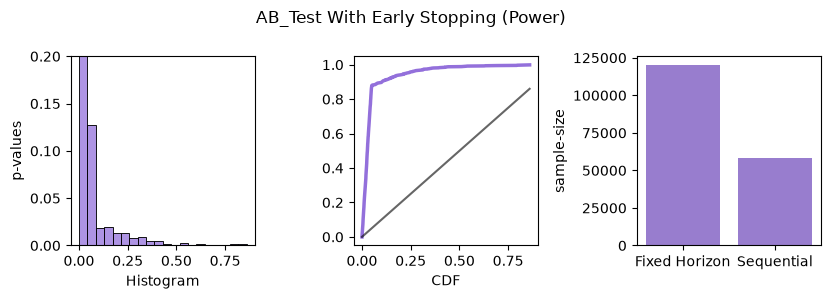

In [16]:
sims_trials = 1000
p_threshold = 0.05
peeking_freq = 10
p_sim_ratio, average_sample_size, p_distribution = abtest_es_power.simulation_func(simulation_trials=sims_trials, 
                                                                    p_threshold = p_threshold, 
                                                                    peeking_freq = peeking_freq)

_ = abtest_dignostic_plot(abtest=abtest_es_power,
                          p_value_log=p_distribution, 
                          fh_sample_size=exp_sample_size,  
                          average_sample_size = average_sample_size, 
                          title = "AB_Test With Early Stopping (Power)")
print(f"For {sims_trials} Simulation Trials Power Rate : {p_sim_ratio} | Average Sample Size: {average_sample_size} ")

In [17]:
# What happens are we peek more (our FPR rate continue to inflate)

sims_trials = 1000
p_threshold = 0.05
peeking_freq = 10

for freq in range(peeking_freq):
    p_sim_ratio, average_sample_size, p_distribution = aatest_es_fpr.simulation_func(simulation_trials=sims_trials, 
                                                                                     p_threshold = p_threshold, 
                                                                                    peeking_freq = freq+1)

    

    print(f"For Peeking Frequency: {freq+1} | {sims_trials} Simulation Trials FPR Rate : {p_sim_ratio} | Average Sample Size: {average_sample_size} ")

For Peeking Frequency: 1 | 1000 Simulation Trials FPR Rate : 0.057 | Average Sample Size: 120000.0 
For Peeking Frequency: 2 | 1000 Simulation Trials FPR Rate : 0.084 | Average Sample Size: 117120.0 
For Peeking Frequency: 3 | 1000 Simulation Trials FPR Rate : 0.099 | Average Sample Size: 115160.0 
For Peeking Frequency: 4 | 1000 Simulation Trials FPR Rate : 0.134 | Average Sample Size: 112080.0 
For Peeking Frequency: 5 | 1000 Simulation Trials FPR Rate : 0.158 | Average Sample Size: 110400.0 
For Peeking Frequency: 6 | 1000 Simulation Trials FPR Rate : 0.141 | Average Sample Size: 111120.0 
For Peeking Frequency: 7 | 1000 Simulation Trials FPR Rate : 0.182 | Average Sample Size: 108051.329 
For Peeking Frequency: 8 | 1000 Simulation Trials FPR Rate : 0.156 | Average Sample Size: 109470.0 
For Peeking Frequency: 9 | 1000 Simulation Trials FPR Rate : 0.201 | Average Sample Size: 105959.929 
For Peeking Frequency: 10 | 1000 Simulation Trials FPR Rate : 0.183 | Average Sample Size: 10681